# A small, testable step toward a quantum network
## Superdense coding: ideal performance, noise, and an honest baseline

**Research question:** Given one pre-shared Bell pair per message, can Alice convey a uniformly chosen two-bit message by physically sending one qubit, and how does depolarizing noise affect decoding?

This notebook simulates standard quantum mechanics; it does **not** test consciousness, identity transfer, wormholes, black holes, faster-than-light signalling, or cosmic-scale communication. Older ideas deserve clear tests, not dismissal by age; a successful simulation checks a model's implications, not whether nature satisfies its assumptions.

### Run in Google Colab
1. Download this `.ipynb`, open [Google Colab](https://colab.research.google.com/), and choose **File → Upload notebook**.
2. Use a standard Python CPU runtime, then **Runtime → Run all**. No account keys, Qiskit, GPU, external datasets, or network downloads are required by the code. NumPy and Matplotlib are included in standard Colab runtimes.
3. Outputs are written to `quantum_network_results/` in that runtime. Download them from Colab's Files panel before its temporary runtime ends.

**Execution provenance:** This deliverable is validated in a local cloud-sandbox Python kernel, not in an actual Colab session or on quantum hardware. Re-running in Colab creates a separate execution.


## What is being compared?

Each message contains two uniformly distributed classical bits, labelled **ab**.

| Scheme | Message-stage channel uses | Additional resources |
|---|---:|---|
| Superdense coding | 1 transmitted qubit | 1 consumed pre-shared Bell pair, local gates, joint decoding |
| Unentangled baseline | 2 transmitted qubits, one per bit | Computational-basis preparation and measurement |

The baseline is a transparent reference protocol, **not** an optimized channel-capacity bound or a classical internet link. Both schemes experience the same single-use noise, but use different numbers of channel uses. Perfect entanglement, gates, memory and measurements are assumed unless the visibility control below is changed. Entanglement distribution/storage costs, loss, latency and hardware overhead are excluded. If creating the Bell pair requires a prior transmitted qubit, the ideal total becomes two transmissions, not one; the apparent factor of two applies to the **message stage** with entanglement already supplied.

### Noise convention
For a single qubit, with $0\leq\lambda\leq1$:
$$D_\lambda(\rho)=(1-\lambda)\rho+\lambda I/2.$$
For a subsystem of a larger state, the code implements the equivalent Pauli mixture:
$$D_\lambda(\rho)=(1-3\lambda/4)\rho+(\lambda/4)(X\rho X+Y\rho Y+Z\rho Z).$$
Thus $\lambda$ is **not** the probability of a nonidentity Pauli error: that probability is $3\lambda/4$. Noise on the two baseline transmissions is independent.

For ideal shared entanglement, predictions are:
- Dense message success: $1-3\lambda/4$.
- Baseline two-bit message success: $(1-\lambda/2)^2$.
- Bit error rate in either scheme: $\lambda/2$ (joint error patterns differ).
- At $\lambda=1$, both message success rates are $1/4$, i.e. guessing one of four messages.

The code computes density-matrix probabilities independently of these formulas, then checks agreement.


In [1]:
from pathlib import Path
import csv
import json
import platform
import sys
import numpy as np
import matplotlib
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt

SEED = 20261020
SHOTS_PER_MESSAGE = 20_000
NOISE_VALUES = np.array([0.0, 0.1, 0.25, 0.5, 0.75, 1.0])
# Visibility v: rho_AB = v|Phi+><Phi+| + (1-v)I4/4.
# v=1 is ideal entanglement; v=0 is fully mixed and uncorrelated.
BELL_VISIBILITY = 1.0
assert 0 <= BELL_VISIBILITY <= 1
rng = np.random.default_rng(SEED)
out_dir = Path('quantum_network_results')
out_dir.mkdir(exist_ok=True)
print('Simulation only; Python', platform.python_version(), '| NumPy', np.__version__)
print(f'{SHOTS_PER_MESSAGE:,} samples per input message, per scheme, per noise setting')


Simulation only; Python 3.12.3 | NumPy 2.5.3
20,000 samples per input message, per scheme, per noise setting


## Explicit qubit order and circuit

The basis is $|AB\rangle=|00\rangle,|01\rangle,|10\rangle,|11\rangle$, with Alice's qubit **first**. For message **ab**, Alice applies $Z^aX^b$ to A (rightmost operator first), then physically sends A. Bob decodes with CNOT(A→B), followed by H(A), and measures in the computational basis. In this convention, the output is **ab**; other textbooks may reverse their bit labels.


In [2]:
I = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.diag([1, -1]).astype(complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
CNOT = np.array([[1,0,0,0], [0,1,0,0], [0,0,0,1], [0,0,1,0]], dtype=complex)
DECODE = np.kron(H, I) @ CNOT
phi = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)
bell = np.outer(phi, phi.conj())

def evolve(rho, U):
    return U @ rho @ U.conj().T

def depolarize(rho, lam, operators):
    assert 0 <= lam <= 1
    return (1 - 3*lam/4)*rho + (lam/4)*sum(evolve(rho, P) for P in operators)

def check_density(rho):
    assert np.allclose(rho, rho.conj().T)
    assert np.isclose(np.trace(rho), 1)
    assert np.linalg.eigvalsh(rho).min() > -1e-10

def measure_probs(rho):
    check_density(rho)
    probs = np.clip(np.diag(rho).real, 0, 1)
    assert np.isclose(probs.sum(), 1)
    return probs / probs.sum()

def dense_confusion(lam, visibility=1.0):
    shared = visibility*bell + (1-visibility)*np.eye(4)/4
    rows = []
    for a in (0, 1):
        for b in (0, 1):
            U = np.kron(np.linalg.matrix_power(Z, a) @ np.linalg.matrix_power(X, b), I)
            encoded = evolve(shared, U)
            transmitted = depolarize(encoded, lam, [np.kron(P, I) for P in (X,Y,Z)])
            rows.append(measure_probs(evolve(transmitted, DECODE)))
    return np.array(rows)

def baseline_confusion(lam):
    rows = []
    for a in (0, 1):
        for b in (0, 1):
            single_probs = []
            for bit in (a,b):
                ket = np.eye(2, dtype=complex)[:, bit]
                rho = np.outer(ket, ket.conj())
                single_probs.append(measure_probs(depolarize(rho, lam, [X,Y,Z])))
            rows.append(np.kron(*single_probs))
    return np.array(rows)

LABELS = ['00', '01', '10', '11']
print('Ideal dense conditional probability matrix (rows sent, columns received):')
print(dense_confusion(0))


Ideal dense conditional probability matrix (rows sent, columns received):
[[1.00000000e+00 0.00000000e+00 5.97792087e-34 0.00000000e+00]
 [0.00000000e+00 1.00000000e+00 0.00000000e+00 5.97792087e-34]
 [5.97792087e-34 0.00000000e+00 1.00000000e+00 0.00000000e+00]
 [0.00000000e+00 5.97792087e-34 0.00000000e+00 1.00000000e+00]]


## Metrics and sampling uncertainty

We report **whole-message success**, **bit error rate**, and **mutual information** $I(M;\hat M)$ for a uniform four-message input. Mutual information is calculated from the exact conditional probabilities, not a finite-sample estimate. Dividing it by message-stage channel uses makes the excluded entanglement resource especially important; this is not an end-to-end capacity claim.

Each row of the conditional probability matrix is sampled separately, with the same number of trials. The plotted 95% Wilson intervals summarize Monte Carlo message-success uncertainty (here each row has the same success probability). They are not uncertainty about the physics or real hardware. No measured experimental data is used.


In [3]:
HAMMING = np.array([[(i ^ j).bit_count() for j in range(4)] for i in range(4)])

def metrics(C):
    assert C.shape == (4, 4) and np.allclose(C.sum(axis=1), 1)
    joint = C / 4
    py = joint.sum(axis=0)
    denom = 0.25 * np.broadcast_to(py, (4, 4))
    mask = joint > 0
    mi = float(np.sum(joint[mask] * np.log2(joint[mask] / denom[mask])))
    return float(np.trace(C)/4), float(np.sum(joint*HAMMING)/2), mi

def wilson(successes, n):
    z = 1.959963984540054
    p = successes / n
    den = 1 + z*z/n
    center = (p + z*z/(2*n)) / den
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / den
    return max(0.0, center-half), min(1.0, center+half)

records = []
for lam in NOISE_VALUES:
    for scheme, C, uses in [
        ('Dense', dense_confusion(lam, BELL_VISIBILITY), 1),
        ('Unentangled baseline', baseline_confusion(lam), 2),
    ]:
        success, ber, mi = metrics(C)
        counts = np.array([rng.multinomial(SHOTS_PER_MESSAGE, row) for row in C])
        n = counts.sum()
        successes = np.trace(counts)
        low, high = wilson(successes, n)
        empirical = counts / SHOTS_PER_MESSAGE
        records.append(dict(scheme=scheme, noise=float(lam), success_exact=success,
                            success_sampled=float(successes/n), ci95_low=low, ci95_high=high,
                            ber_exact=ber, ber_sampled=metrics(empirical)[1],
                            mutual_information_bits=mi, message_stage_channel_uses=uses,
                            info_per_message_stage_use=mi/uses))
print(f"{'scheme':23s} {'lambda':>6s} {'P(success)':>11s} {'sampled':>9s} {'BER':>7s} {'MI bits':>8s}")
for r in records:
    print(f"{r['scheme']:23s} {r['noise']:6.2f} {r['success_exact']:11.4f} "
          f"{r['success_sampled']:9.4f} {r['ber_exact']:7.4f} {r['mutual_information_bits']:8.4f}")


scheme                  lambda  P(success)   sampled     BER  MI bits
Dense                     0.00      1.0000    1.0000  0.0000   2.0000
Unentangled baseline      0.00      1.0000    1.0000  0.0000   2.0000
Dense                     0.10      0.9250    0.9259  0.0500   1.4968
Unentangled baseline      0.10      0.9025    0.9029  0.0500   1.4272
Dense                     0.25      0.8125    0.8123  0.1250   1.0066
Unentangled baseline      0.25      0.7656    0.7661  0.1250   0.9129
Dense                     0.50      0.6250    0.6245  0.2500   0.4512
Unentangled baseline      0.50      0.5625    0.5618  0.2500   0.3774
Dense                     0.75      0.4375    0.4363  0.3750   0.1198
Unentangled baseline      0.75      0.3906    0.3893  0.3750   0.0911
Dense                     1.00      0.2500    0.2513  0.5000   0.0000
Unentangled baseline      1.00      0.2500    0.2473  0.5000   0.0000


## Automated checks: try to break the interpretation

The checks cover bit ordering, normalization/positivity, analytic predictions, the completely noisy endpoint, and no signalling before a qubit is sent. Tracing out Alice's qubit leaves Bob with the same marginal state for every encoded message. A maximally mixed, uncorrelated pair also destroys dense decoding. These are model consistency checks, not new experimental evidence for no signalling.


In [4]:
assert np.allclose(dense_confusion(0), np.eye(4))
assert np.allclose(baseline_confusion(0), np.eye(4))
for lam in np.linspace(0, 1, 21):
    d_success, d_ber, _ = metrics(dense_confusion(lam))
    b_success, b_ber, _ = metrics(baseline_confusion(lam))
    assert np.isclose(d_success, 1 - 3*lam/4)
    assert np.isclose(b_success, (1-lam/2)**2)
    assert np.isclose(d_ber, lam/2) and np.isclose(b_ber, lam/2)
    # Visibility control has its own independently predicted success curve.
    assert np.isclose(metrics(dense_confusion(lam, 0.6))[0], (1+3*0.6*(1-lam))/4)
assert np.allclose(dense_confusion(1), np.ones((4,4))/4)
assert np.allclose(baseline_confusion(1), np.ones((4,4))/4)
assert np.allclose(dense_confusion(0, visibility=0), np.ones((4,4))/4)
# rho[A,B,A',B']; tracing A and A' leaves Bob's reduced density matrix.
for a in (0,1):
    for b in (0,1):
        U = np.kron(np.linalg.matrix_power(Z,a) @ np.linalg.matrix_power(X,b), I)
        encoded = evolve(bell, U)
        bob_marginal = np.trace(encoded.reshape(2,2,2,2), axis1=0, axis2=2)
        assert np.allclose(bob_marginal, I/2)
# Broad reproducible sanity bound, not a requirement that every 95% CI cover truth.
for r in records:
    n = 4*SHOTS_PER_MESSAGE
    se = np.sqrt(r['success_exact']*(1-r['success_exact'])/n)
    assert abs(r['success_sampled']-r['success_exact']) <= 6*se + 1/n
print('PASS: ideal decoding, noise formulas, bit errors, visibility, endpoints, no signalling, sampling.')


PASS: ideal decoding, noise formulas, bit errors, visibility, endpoints, no signalling, sampling.


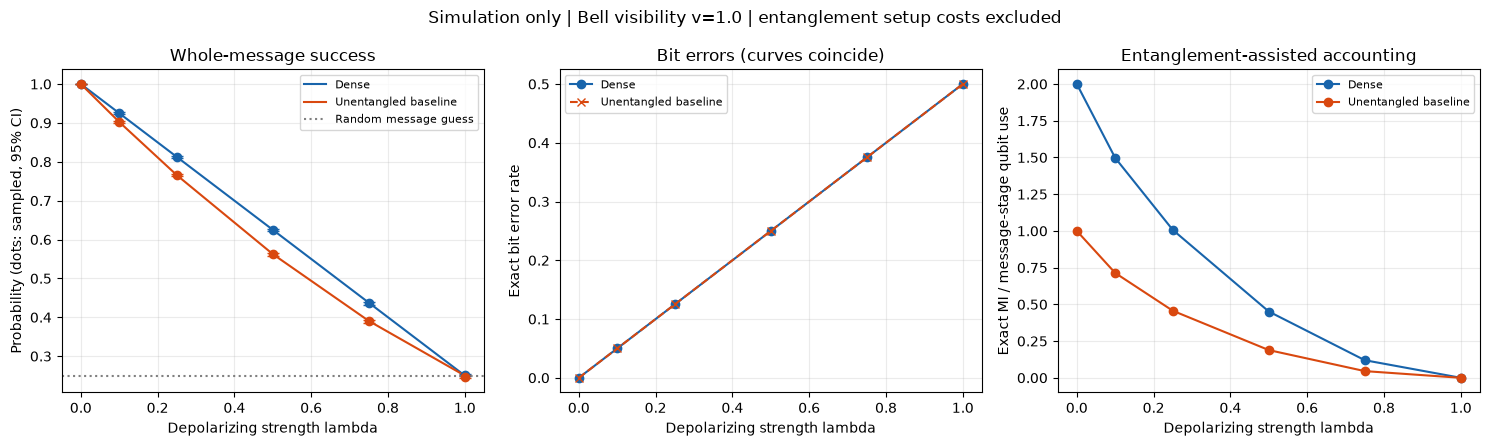

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for scheme, color in [('Dense', '#1864ab'), ('Unentangled baseline', '#d9480f')]:
    subset = [r for r in records if r['scheme'] == scheme]
    xs = np.array([r['noise'] for r in subset])
    exact = np.array([r['success_exact'] for r in subset])
    sampled = np.array([r['success_sampled'] for r in subset])
    lower = sampled - np.array([r['ci95_low'] for r in subset])
    upper = np.array([r['ci95_high'] for r in subset]) - sampled
    axes[0].plot(xs, exact, '-', color=color, label=scheme)
    axes[0].errorbar(xs, sampled, yerr=[lower,upper], fmt='o', capsize=4, color=color)
    axes[1].plot(xs, [r['ber_exact'] for r in subset], 'o-' if scheme == 'Dense' else 'x--',
                 color=color, label=scheme)
    axes[2].plot(xs, [r['info_per_message_stage_use'] for r in subset], 'o-', color=color, label=scheme)
axes[0].axhline(0.25, color='gray', linestyle=':', label='Random message guess')
for ax, title, ylabel in zip(axes,
    ['Whole-message success', 'Bit errors (curves coincide)', 'Entanglement-assisted accounting'],
    ['Probability (dots: sampled, 95% CI)', 'Exact bit error rate', 'Exact MI / message-stage qubit use']):
    ax.set(title=title, xlabel='Depolarizing strength lambda', ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle(f'Simulation only | Bell visibility v={BELL_VISIBILITY} | entanglement setup costs excluded')
fig.tight_layout()
fig.savefig(out_dir / 'simulation_metrics.png', dpi=160, bbox_inches='tight')
plt.show()


## What a result means—and what it does not

With ideal entanglement and no noise, dense coding recovers all four messages using one **message-stage** qubit transmission; the baseline needs two. Under this noise model the dense whole-message success is higher than the baseline for $0<\lambda<1$, although their bit error rates coincide. The same bit error rate can give different whole-message reliability because the two bits have different joint error patterns. Resource-normalized information is another distinct metric. Nonzero errors do not establish that error correction is impossible; no quantum error-correcting code is implemented here.

At maximal noise, neither scheme carries message information. Shared entanglement alone also does not reveal the message to Bob before Alice sends her qubit. None of these results support instantaneous communication or transfer of consciousness.

**Useful next tests:** change `BELL_VISIBILITY`, noise strengths, or sample count and rerun everything; then introduce gate/memory noise or loss with an explicit erasure outcome. An error-correction extension should compare logical versus physical error rates **at a stated physical-qubit, gate, time and transmission budget**, including entanglement distribution and recovery overhead. Simulations can rank such designs under assumptions; hardware measurements are needed to test those assumptions in nature.

### Sources and evidence boundaries
- [IBM Quantum: superdense coding](https://quantum.cloud.ibm.com/learning/courses/basics-of-quantum-information/entanglement-in-action/superdense-coding): the protocol, consumed e-bit, transmitted qubit and unassisted one-bit limit.
- [Qiskit Aer: depolarizing channel](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.depolarizing_error.html): channel convention. This notebook implements the matrices directly rather than relying on Qiskit.

The numeric outputs below are synthetic simulation results, not external experimental data.


In [6]:
with (out_dir / 'metrics.csv').open('w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=list(records[0]))
    writer.writeheader()
    writer.writerows(records)
summary = dict(execution='Local sandbox Python kernel; not actual Colab or quantum hardware',
               seed=SEED, shots_per_message=SHOTS_PER_MESSAGE,
               bell_visibility=BELL_VISIBILITY, noise_values=NOISE_VALUES.tolist(),
               python=sys.version, numpy=np.__version__, matplotlib=matplotlib.__version__,
               checks='all automated assertions passed',
               assumptions=['independent depolarizing message channels', 'ideal gates and readout',
                            'no loss', 'entanglement distribution and memory costs excluded'])
(out_dir / 'validation_summary.json').write_text(json.dumps(summary, indent=2)+'\n')
print('Saved:', ', '.join(str(p) for p in sorted(out_dir.iterdir())))
print('Local validation complete. A Colab run has not been performed.')


Saved: quantum_network_results/metrics.csv, quantum_network_results/simulation_metrics.png, quantum_network_results/validation_summary.json
Local validation complete. A Colab run has not been performed.
